# Challenge 3

In [1]:
%pip install qiskit qiskit-aer

Note: you may need to restart the kernel to use updated packages.


In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
from IPython.display import display

**Prediction — Original Circuit**

The circuit starts in the state |00⟩. The H gate creates a superposition on qubit 0, and the CNOT gate entangles the two qubits. I expect the measurement outcomes 00 and 11 to occur approximately 50 times each out of 100 shots. The outcomes 01 and 10 should not occur in an ideal simulator.


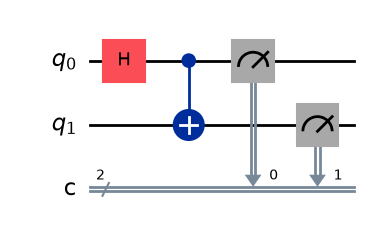

In [3]:
# Original Bell-state circuit
original = QuantumCircuit(2, 2)

original.h(0)
original.cx(0, 1)

# Measure both qubits
original.measure(0, 0)
original.measure(1, 1)

# Display the circuit
display(original.draw(output="mpl"))

In [4]:
simulator = AerSimulator()

result_original = simulator.run(
    original, shots=100
).result()

counts_original = result_original.get_counts()

print("Original circuit results:", counts_original)

plot_histogram(
    counts_original,
    title="Original Bell-State Circuit"
)
plt.show()

Original circuit results: {'11': 54, '00': 46}


**Prediction — Modified Circuit**

I will add one X gate to qubit 0 after the CNOT gate. The X gate flips qubit 0, changing the Bell-state outcomes from 00 and 11 to 10 and 01 when written in qubit order (q0, q1). Therefore, I expect outcomes 01 and 10 to occur approximately 50 times each. The qubits should now produce opposite values.


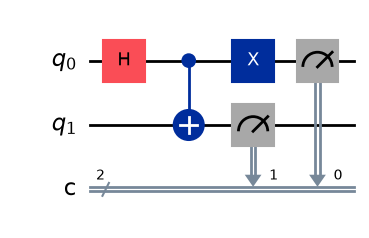

In [5]:
# Modified Bell-state circuit
modified = QuantumCircuit(2, 2)

modified.h(0)
modified.cx(0, 1)

# Added gate: X on qubit 0
modified.x(0)

# Measure both qubits
modified.measure(0, 0)
modified.measure(1, 1)

# Display the circuit
display(modified.draw(output="mpl"))

In [6]:
result_modified = simulator.run(
    modified, shots=100
).result()

counts_modified = result_modified.get_counts()

print("Modified circuit results:", counts_modified)

plot_histogram(
    counts_modified,
    title="Modified Bell-State Circuit"
)
plt.show()

Modified circuit results: {'01': 49, '10': 51}


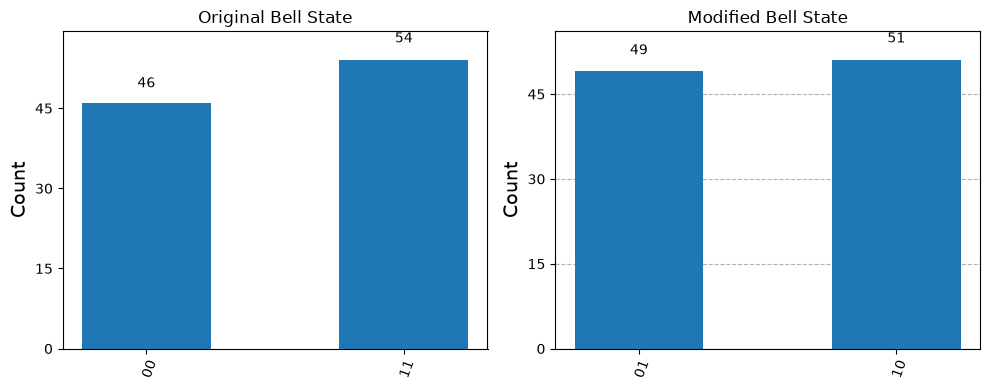

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

plot_histogram(counts_original, ax=axes[0])
axes[0].set_title("Original Bell State")

plot_histogram(counts_modified, ax=axes[1])
axes[1].set_title("Modified Bell State")

plt.tight_layout()
plt.show()

# Conclusion

In this experiment, two-qubit quantum circuits were created and simulated using Qiskit with 100 shots per circuit.

The original Bell-state circuit used an H gate followed by a CNOT gate. It produced correlated measurement outcomes, with both qubits giving the same value. The expected outcomes were 00 and 11.

In the modified circuit, one X gate was added to qubit 0 after the CNOT gate. This gate flipped the value of qubit 0, changing the possible measurement outcomes to 01 and 10. The two qubits therefore produced opposite values.

The histograms helped demonstrate the change in measurement outcomes. This experiment shows that modifying a single quantum gate can change the measurement relationship between qubits. The original circuit produces correlated outcomes, while the modified circuit produces anti-correlated outcomes.
